In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
%matplotlib widget

# Modeling Epileptic seizures using TVB

**EITN Fall School in Computational Neuroscience, 20-29 Sep 2023 Paris**

## Context

TVB can be used to model **large-scale epileptic seizure dynamics**. Using relevant neural mass models, TVB allows to ask multiple questions such as the **localisation of the Epileptogenic Zone** or the **validity of different neuroimaging modalities** to assess the epileptogenicity of a brain structure. Here, we will present an example of such a modelisation.

## Objectives

The main goal of this tutorial is to provide a clear understanding of **how we can reproduce clinically relevant senarios** such as the modelisation of **propagation of an epileptic seizure** in the human brain, **surgical resection** of brain regions, and **electrical stimulation** of a brain region that can trigger a seizure.

## How to do it with TVB?

The first thing we want to do is to import the modules we will need for a simulation.

In [3]:
%%capture
# Import a bunch of stuff to ease command line usage.
from tvb.simulator.lab import *
from tvb.datatypes.time_series import TimeSeriesRegion
import tvb.datatypes.projections as projections
from utils import plot_connectivity, initial_conditions
from tvbwidgets.api import PhasePlaneWidget

import numpy as np
import matplotlib.pylab as plt
import os
import time as tm

# 1. Exploring the Epileptor model

In order to model epilepsy, we choose the **Epileptor** which is a phenomenological neural mass model able to realistically reproduce **epileptic seizure dynamics** such as recorded with intracranial EEG electrodes (see **Jirsa et al., Brain 2014**).

$$
\begin{align}
\dot{x}_{1,i} &=  y_{1,i} - f_1(x_{1,i},x_{2,i}) -z_i + I_{ext,i} \\
\dot{x}_{1,i} &= 1 - 5x_{1,i}^2 - y_{1,i}\\
\dot{z_{i}} &= \frac{1}{\tau_0} (4(x_{1,i}-x_{0,i}) -z_i - K_s \sum C_{ij}(x_{1,j}-x_{1,i}) \\
\dot{x}_{2,i} &= -y_{2,i} + x_{2,i} - x^3_{3,i}+I_{ext,i} + 0.002g(x_{1,i}) - 0.3 (z_i - 3.5)\\
\dot{y}_{2,i} &= \frac{1}{\tau_{2}} (-y_{2,i} + f_2(x_{2,i})).
\end{align}
$$

Before launching any simulations, we will have a look at the **phase space** of the model in order to better understand its dynamics. We will use the phase plane interactive tool.

In [4]:
# Create an Epileptor model instance.
epi = models.Epileptor()

# Initialise an Integrator scheme.
dt = 0.075    #integration steps [ms]
heunint = integrators.HeunDeterministic(dt=dt)

# Open the phase plane tool with the Epileptor model.
w = PhasePlaneWidget(model=epi, integrator=heunint)
w.TRAJ_STEPS = 6000
w.get_widget()

Look at the phase space: 

We have here the **first population** (variables $\pmb{x_{1}}$ in abscissa and $\pmb{y_{1}}$ in ordinate).

The left most intersection of the two nullclines defines a **stable fixed point**, representing the **interictal state (i.e., between seizures)**, whereas the right most intersection is the center of a **limit cycle**, being the **ictal state (i.e., during seizures)**. Both states are separated by a separatrix, as you can se by drawing different trajectories in this phase space.

You can also have a look at other variables in the phase space, such as the **second population** (variables $\pmb{x_{2}}$ in abscissa and $\pmb{y_{2}}$ in ordinate), responsible for the **interictal spikes** in the Epileptor model. Change the lower and upper bound of the axis to see correctly the phase space.

You can continue to play along to explore the dynamics of this model. For instance, try changing the number of integration steps, or choosing a HeunStochastic integrator and varying the scaling of the noise:

In [5]:
epi = models.Epileptor()
# Initialise a stochastic Integrator scheme.
dt = 0.005                                           #integration steps [ms]
heunstochint = integrators.HeunStochastic(dt=dt)
heunstochint.noise.nsig = np.r_[0.05]                      #standard deviation of the noise 

# Open the phase plane tool with the Epileptor Model and stochastic Integrator.
w = PhasePlaneWidget(model=epi, integrator=heunstochint)
w.noise_slider_valinit = w.integrator.noise.nsig[0]
w.TRAJ_STEPS = 6000
w.get_widget()

# 2. Dataset
We will use the **default dataset** that is supplied with The Virtual Brain. To make things fully transparent, we will load the files from our local copy. To follow, change the path to the location of the dataset on your machine:

In [6]:
datadir = os.path.abspath("./dataset")

# 3. Region-based modeling of an epileptic patient

In the following, we will model a patient with a **bilateral temporal lobe epilepsy (TLE)** using the Default TVB Subject.

The basic simulation of TVB consists of 5 main components. Each of these components is an object within TVB:

## 3.1 Structural Connectivity

We start with loading and visualizing the structural connectivity matrix.

In [7]:
# Initialise a Connectivity.
con = connectivity.Connectivity.from_file(os.path.join(datadir, "connectivity_76.zip"))       
nregions = len(con.areas)                                  #number of regions
con.weights = con.weights - con.weights * np.eye(nregions) #remove self-connections
con.weights = con.weights / np.abs(con.weights.max())      #normalize
con.speed = np.array(np.inf)                                         #set the conduction speed to infinity (i.e., no time delay)
con.configure()

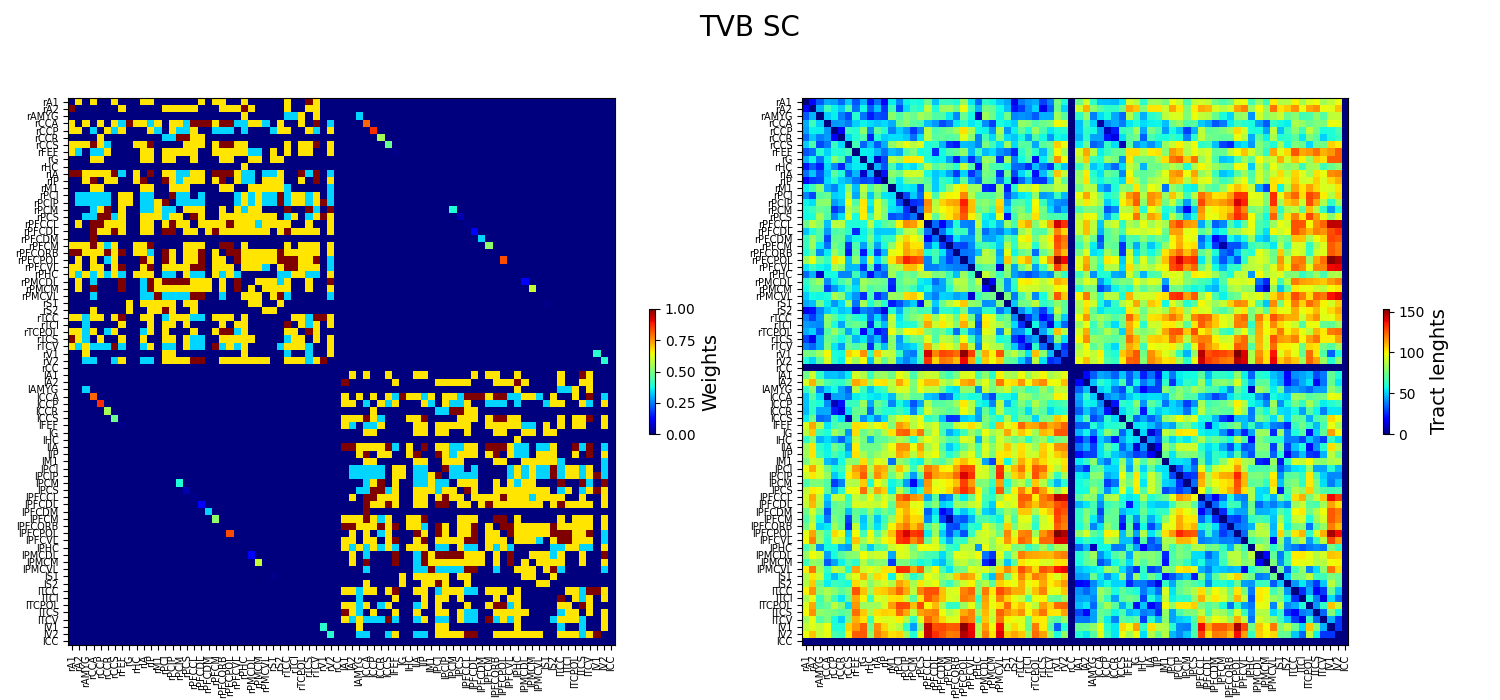

In [8]:
# Visualization.
plot_connectivity(con)

## 3.2 Model

A set of differential equations describing the local dynamics. Here, we use the **Epileptor**.

In [9]:
# Initialise a Model.
epi = models.Epileptor(Ks=np.array(1.), r=np.array(0.00015))

We can refine the network pathology of the patient by including the hypothesis about the Epileptogenic Network. To this end, we define a **spatial map of epileptogenicity** where each network's node $i$ is characterized by an excitability value $\pmb{x_{0,i}}$, which quantifies its ability to trigger a seizure. 

We set:

* the hippocampus (rHC, region 9 and lHC, region 47) as well as the amydala (rAMYG, region 2 and lAMYG, region 40) as **Epileptogenic Zone (EZ)**, with an epileptogenicity parameter value $\pmb{x_{0,i}}$ equal to **-0.75** for the rHC and **-1.65** for the lHC and l-rAMYG,
* we also add two lesser epileptogenic regions: the parahippocampal (lPHC, region 62) and the temporal pole (lTPOL, region 70) as **Propagation Zone (PZ)**, with an epileptogenicity parameter value $\pmb{x_{0,i}}$ equal to **-1.78** and **-1.81**, respectively,
* and all the other regions (or **Non-Epileptogenic Zone, NEZ**) are set to **-2.6**.



In [10]:
# Define a heatmap.
epi.x0 = np.ones(nregions) * (-2.6)            #NEZ
epi.x0[[9]] = np.ones((1)) * (-0.75)           #EZ 
epi.x0[[47, 2, 40]] = np.ones((3)) * (-1.65)   #EZ 
epi.x0[[62]] = np.ones((1)) * (-1.78)          #PZ 
epi.x0[[70]] = np.ones((1)) * (-1.81)          #PZ 

## 3.3 Coupling function

It is a function that is used to join the local model dynamics at distinct spatial locations.

We couple the Epileptors by permittivity coupling, which quantifies the influence of neuronal fast discharges $x_{1,j}$ of a remote region $j$ on the local slow permittivity variable $z_{i}$ of region $i$ via a linear **difference coupling** function.

In [11]:
# Initialise a Coupling function.
G = np.array(-0.25)      #global (long-range) coupling strength
con_coupling = coupling.Difference(a=G)

## 3.4 Integrator

We use a stochastic integration scheme, and the noise is added. The shape of the noise must correspond to the number of state-variables in the neural mass model, here equal to 6.

We employ a standard <b>Heun method</b> with an integration time step of <b>0.05</b>. <b>Additive white Gaussian noise</b> is introduced in the state-variables $\pmb{x_{2,i}}$ and $\pmb{y_{2,i}}$ with 0 mean and variance <b>0.00025</b>. Other variables experience only little or no noise due to their high density.

In [12]:
# Initialise an Integrator scheme.
dt = 0.05               #integration steps [ms]
nsigma = 0.0001        #standard deviation of the noise

hiss = noise.Additive(nsig=np.array([0., 0., 0., nsigma, nsigma, 0.])) 
heunint = integrators.HeunStochastic(dt=dt, noise=hiss)

## 3.5 Monitors

The last component we need to define are some Monitors. Monitors are measurement processes applied to the output data from the simulation.


Here, we will select (1) a simple data reduction and (2) a biophysical measurement process to relate the simulated neural activity to recent epilepsy studies: 

1. the <b>TemporalAverage</b> monitor averages over a time window of length <i>period</i> returning one time point every <i>period</i> ms,
2. the <b>iEEG</b> monitor generates SEEG recordings.

In [13]:
# Initialise some Monitors with period in physical time.
mon_tavg = monitors.TemporalAverage(period=1) #in ms

mon_seeg = monitors.iEEG.from_file(
    sensors_fname=os.path.join(datadir, "seeg_588.txt"),
    projection_fname=os.path.join(datadir, "projection_seeg_588_surface_16k.npy"),
    rm_f_name=os.path.join(datadir, "regionMapping_16k_76.txt"),
    period=1.)

what_to_watch = (mon_tavg, mon_seeg)

In [14]:
# Set initial conditions.
svar_range = {
    "x1": [-1.8, -1.4],
    "y1": [-15., -10.],
    "z": [3.6, 4.],
    "x2": [-1.1, -0.9],
    "y2": [0.001, 0.01],
}
init_cond = initial_conditions(epi, con, dt, svar_range)

***

# Go! Simulate

We can then configure and run the <b>Simulator</b>.

In [15]:
# Initialise the Simulator.
sim = simulator.Simulator(model=epi,
                          connectivity=con,
                          conduction_speed=np.float(con.speed),
                          coupling=con_coupling,
                          integrator=heunint,
                          initial_conditions=init_cond,
                          monitors=what_to_watch)

sim.configure()

/tmp/ipykernel_902/3993696054.py:4: DeprecationWarning: `np.float` is a deprecated alias for the builtin `float`. To silence this warning, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  conduction_speed=np.float(con.speed),


In [16]:
# Starting simulation.
print("Starting simulation...")
tic = tm.time()
(ttavg, tavg), (tseeg, seeg) = sim.run(simulation_length=6000)

# Finished simulation. 
print("Finished simulation.")
print("execute for" + str(tm.time()-tic))

Starting simulation...
Finished simulation.
execute for56.27901577949524


***

# Visualize our simulation

And finally, we can look at the results of our simulation in terms of time series:

In [17]:
# Normalize the time series to have nice plots.
tavg /= (np.max(tavg,0) - np.min(tavg,0 ))
tavg -= np.mean(tavg, 0)
seeg /= (np.max(seeg,0) - np.min(seeg, 0))
seeg -= np.mean(seeg, 0)

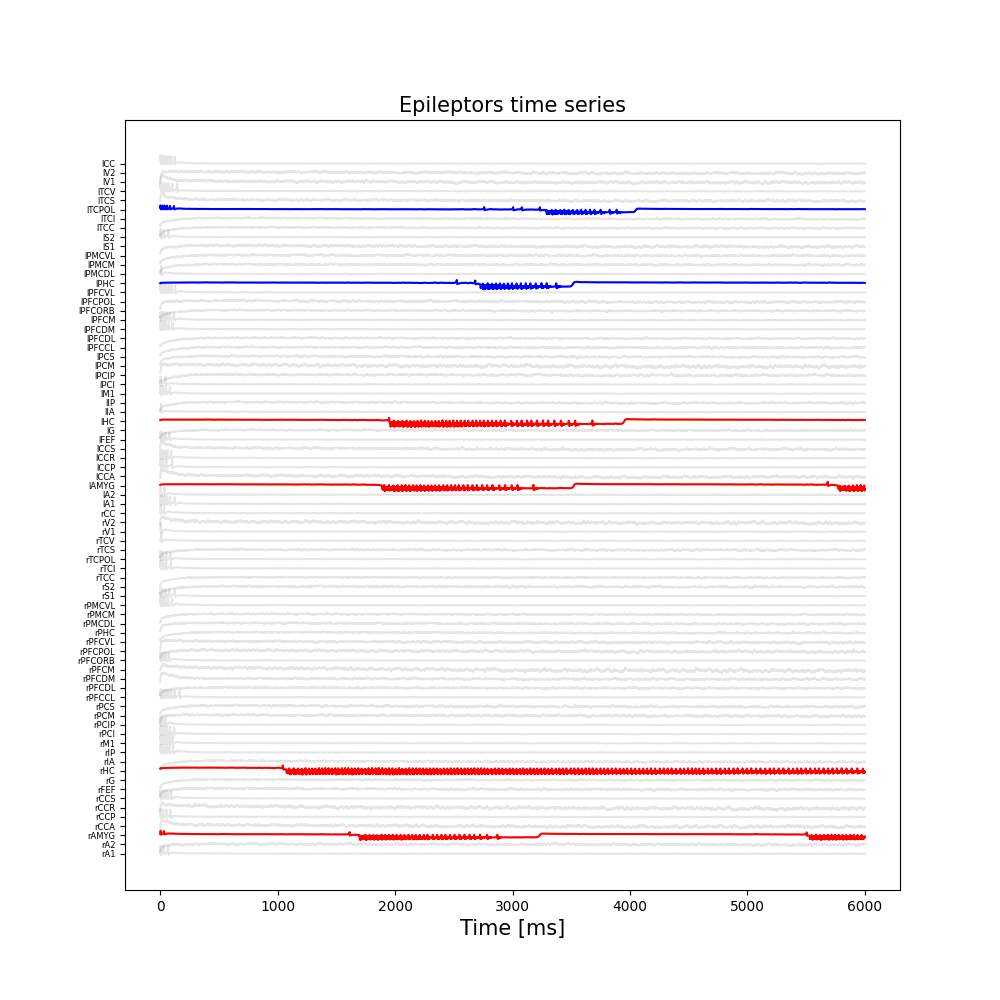

In [18]:
# Plot neural activity time series.
plt.figure(figsize=(10,10))
plt.plot(ttavg[:], tavg[:, 0, :, 0] + np.r_[:nregions], 'k', alpha=0.1)
plt.title('Epileptors time series', fontsize=15)
plt.xlabel('Time [ms]', fontsize=15)
plt.yticks(np.arange(len(con.region_labels)), con.region_labels, fontsize=6)

EZs = [9, 47, 2, 40]
for ie, ez in enumerate(EZs):
    plt.plot(ttavg[:], tavg[:, 0, EZs[ie], 0] + EZs[ie], 'r') # , 'C3'
PZs = [62, 70]
for ip, pz in enumerate(PZs):
    plt.plot(ttavg[:], tavg[:, 0, PZs[ip], 0] + PZs[ip], 'b') # , 'C0'    

Text(0.5, 0, 'Time [ms]')

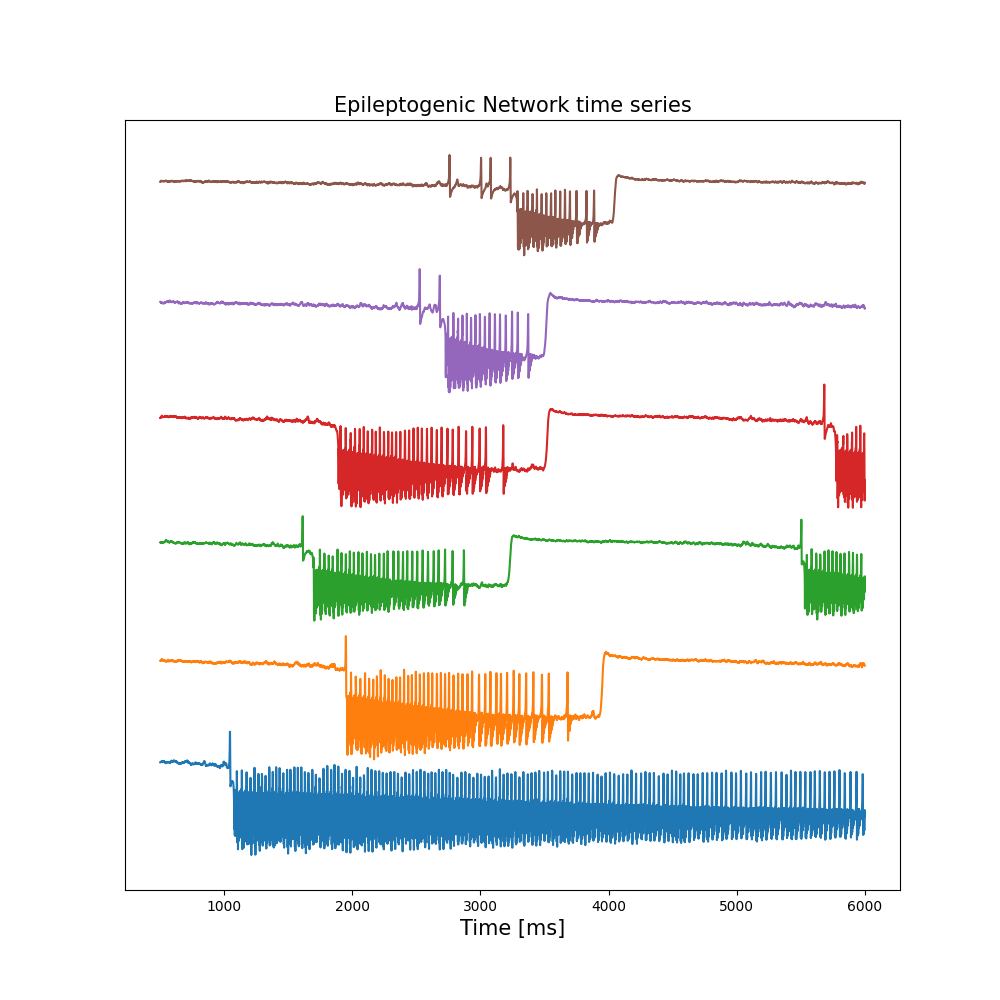

In [19]:
# Zoom on the propagation pattern.
EN = [9, 47, 2, 40, 62, 70]
idx = np.arange(len(EN))

plt.figure(figsize=(10,10))
for ie, en in enumerate(EN):
    plt.plot(ttavg[500:], tavg[500:, 0, EN[ie], 0] + idx[ie]) # , 'C0'
    plt.yticks([])
plt.title('Epileptogenic Network time series', fontsize=15)
plt.xlabel('Time [ms]', fontsize=15)

Text(0.5, 0, 'Time [ms]')

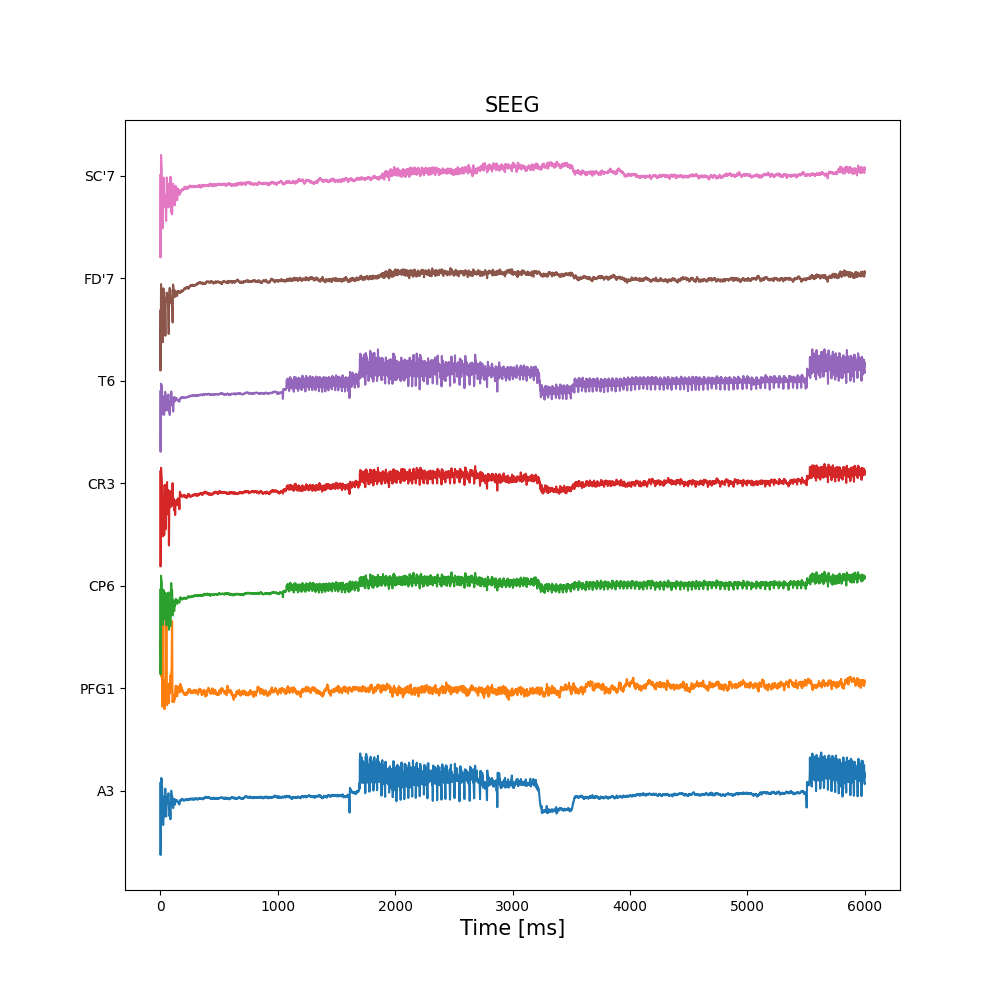

In [20]:
# Plot some of the SEEG sensors.
electrodes = [20, 90, 140, 200, 290, 480, 540]

plt.figure(figsize=(10,10))
plt.plot(tseeg[:], seeg[:, 0, electrodes, 0] + np.r_[:len(electrodes)]) # , 'C0'
plt.yticks(np.r_[:len(electrodes)], mon_seeg.sensors.labels[electrodes])
plt.title('SEEG', fontsize=15)
plt.xlabel('Time [ms]', fontsize=15)

# 4. Modeling surgical resection

Surgical resection is used for around 20% of epileptic patient whose seizures are drug- resistant. We will simulate the hypothetic case of a surgical resection of the Epileptogenic Zone.

## 4.1 Resection

We set all the connections to the Epileptogenic Zone to 0 in the connectivity matrix. The resection of the Epileptogenic Network is not complete, will it be enough to prevent seizures?

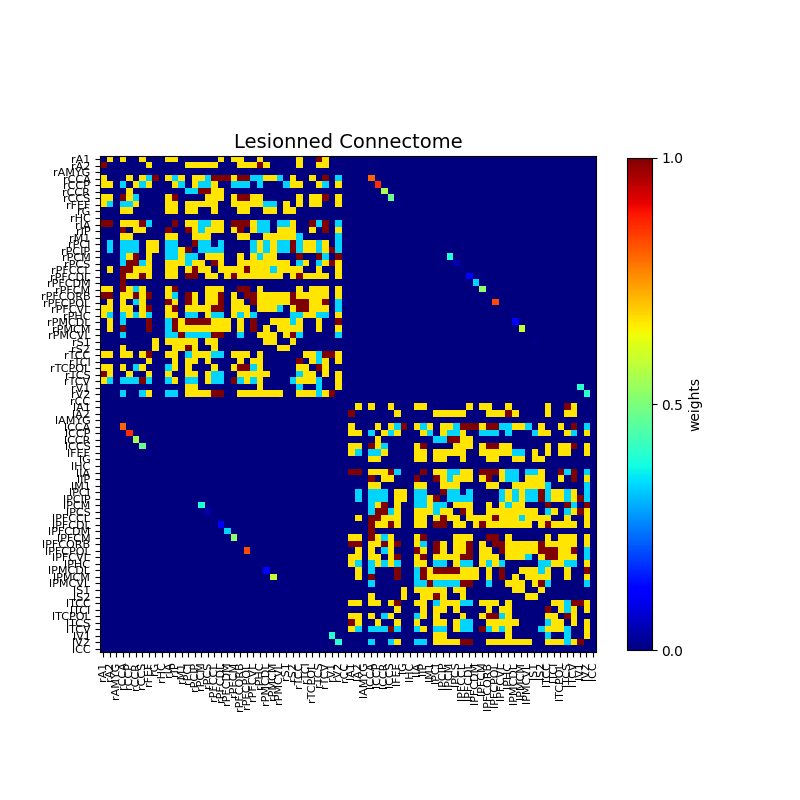

In [21]:
# All the incoming and outcoming connections of the resected regions are removed:
con.weights[:, [9, 47, 2, 40]] = 0.
con.weights[[9, 47, 2, 40], :] = 0.
con.configure()

# Visualization of the resected connectome.
plt.figure(figsize=(8,8))
plt.imshow(con.weights, interpolation='nearest', aspect='equal', cmap='jet')
plt.title('Lesionned Connectome', fontsize=14)
cb=plt.colorbar(shrink=0.8, ticks=[0, 0.5, 1])
cb.set_label('weights')
plt.xticks(range(0, nregions), con.region_labels, fontsize=8, rotation=90)
plt.yticks(range(0, nregions), con.region_labels, fontsize=8);

## 4.2 Simulate

We can now relaunch our first simulation, taking care of replacing the dynamic of the EZ by a stable node, as if the region was resected. The rest of the model is set as before, but we just use a time average monitor.

In [22]:
# Initialise the Model.
epi = models.Epileptor(Ks=np.array(1.), r=np.array(0.00015))

# Define heatmap.
epi.x0 = np.ones(nregions) * (-2.6)       #NEZ
epi.x0[[62]] = np.ones((1)) * (-1.78)     #PZ 
epi.x0[[70]] = np.ones((1)) * (-1.81)     #PZ 

# Set initial conditions.
svar_range = {
    "x1": [-1.8, -1.8],
    "y1": [-15., -15.],
    "z": [3.6, 3.6],
    "x2": [-1.1, -1.1],
    "y2": [0.001, 0.001],
}
init_cond = initial_conditions(epi, con, dt, svar_range)

In [23]:
# Initialise the Simulator.
sim = simulator.Simulator(model=epi,
                          connectivity=con,
                          conduction_speed=con.speed.item(),
                          coupling=coupling.Difference(a=np.array(-0.25)),
                          integrator=integrators.HeunStochastic(dt=0.05 , noise=noise.Additive(nsig=np.array([0., 0., 0., 0.00025, 0.00025, 0.]))),
                          initial_conditions=init_cond,
                          monitors=(monitors.TemporalAverage(period=1),))

sim.configure()

In [24]:
# Starting simulation
print("Starting simulation...")
tic = tm.time()

(ttavg, tavg), = sim.run(simulation_length=10000) # ~ 73 s

# Finished simulation. 
print("Finished simulation.")
print("execute for " + str(tm.time()-tic))

Starting simulation...
Finished simulation.
execute for 76.39631509780884


## 4.3 Visualize

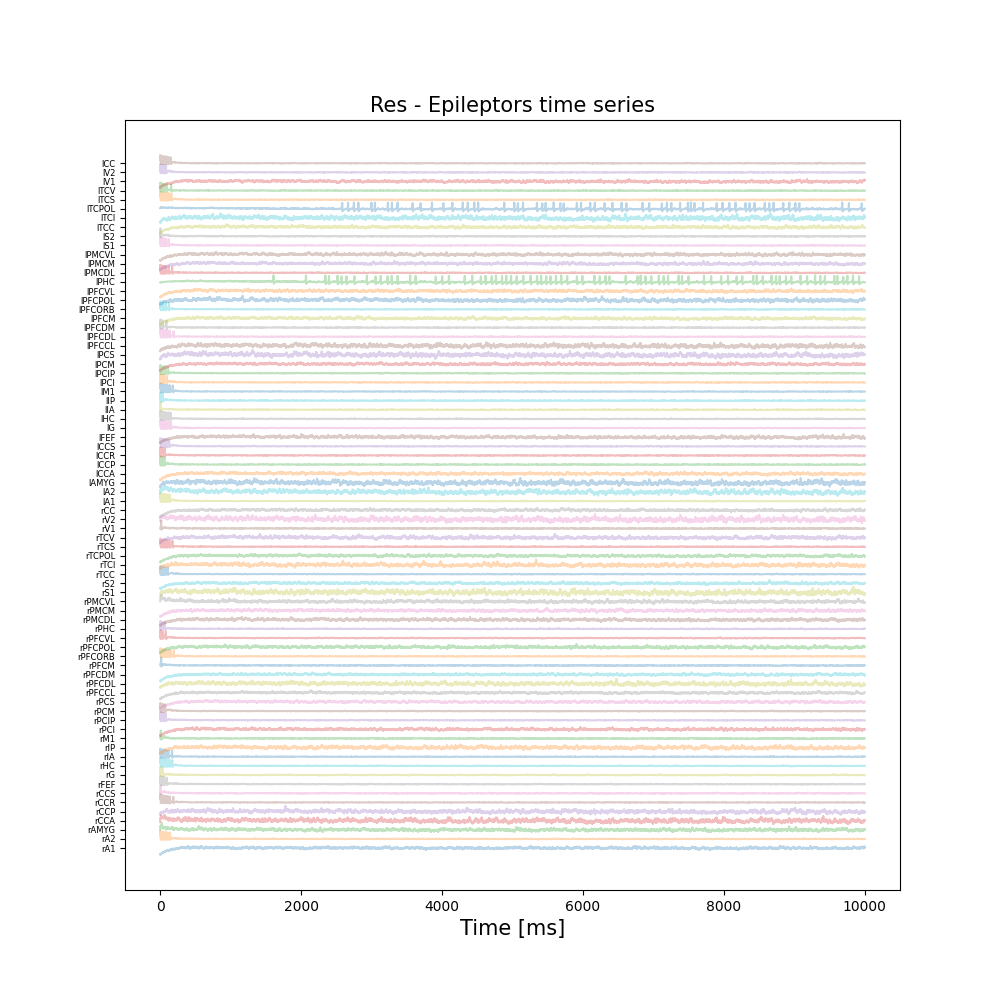

In [25]:
# Normalize the time series to have nice plots.
tavg /= (np.max(tavg,0) - np.min(tavg,0 ))
tavg -= np.mean(tavg, 0)

# Plot time series.
plt.figure(figsize=(10,10))
plt.plot(ttavg[:], tavg[:, 0, :, 0] + np.r_[:nregions], alpha=0.3) # , 'C2'
plt.title('Res - Epileptors time series', fontsize=15)
plt.xlabel('Time [ms]', fontsize=15)
plt.yticks(np.arange(len(con.region_labels)), con.region_labels, fontsize=6);

As you can see, no seizure is triggered anymore.

# 5. Triggering a seizure by stimulation

We are now going to model an <b>electric stimulation</b> and <b>trigger a seizure</b>. We set the whole brain to non-epileptogenic but the stimulated regions are set closer to the threshold.

# 5.1 Build a stimulus

We will begin by just arbitrarily selecting some nodes and defining the weighting of the stimuli coming into those nodes, to show what the basic process looks like.

In [26]:
# Configure stimulus spatial pattern.
nodes = [62, 70]
stim_weights = np.zeros((nregions))
stim_weights[nodes] = np.array([2.0])

We now need to define the temporal profile. This is done by selecting an equation and setting its parameters as desired.

In [27]:
# Configure stimulus temporal profile.
eqn_t = equations.PulseTrain()
eqn_t.parameters['onset'] = 2e3       # onset time [ms]
eqn_t.parameters['T'] = 3000.0        # pulse repetition period [ms]
eqn_t.parameters['tau'] = 100.0       # pulse duration [ms]

Now, we need to combine these spatial and temporal components into a StimuliRegion object, which can then be used in the construction of our simulator:

In [28]:
# Configure Stimuli object.
stimulus = patterns.StimuliRegion(temporal = eqn_t,
                                  connectivity = con, 
                                  weight =stim_weights)

We can take a quick look at the basic structure of the stimuli we have just defined using one of the built in plotting tools.

The plotting tool we will use provides a simple overview of the stimuli's structure. It assumes the stimulus object is already configured, so we start by configuring the object. This configuration step is actually taken care of automagically within the simulator, so when you don't want to look at your stimuli before running a simulation this step isn't necessary.

<i>NOTE:</i> while the information necessary to configure space is provided by the Connectivity object, for time it is necessary to explicitly provide a time vector. When a simulation is run, this time vector is generated internally based on the integration scheme's dt and the simulation length requested when you call the simulator.

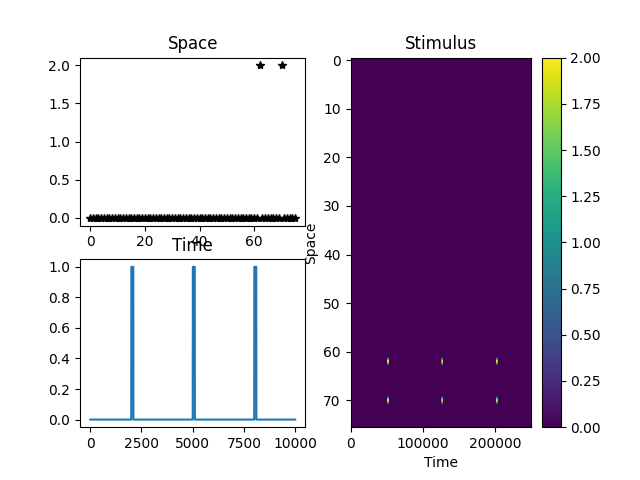

In [29]:
# Configure space and time.
stimulus.configure_space()
stimulus.configure_time(np.arange(0., 10000., 5**-2))

# And take a look
plot_pattern(stimulus)

## 5.2 Simulate

Now, we just configure ...

In [30]:
dt = 0.05
# Initialise Model.
epi = models.Epileptor(Ks=np.array(1.), r=np.array(0.00015))
epi.x0 = np.ones(nregions) * (-2.2) 
epi.x0[nodes] = np.ones((2)) * (-2.07)

svar_range = {
    "x1": [-1.8, -1.8],
    "y1": [-15., -15.],
    "z": [3.6, 3.6],
    "x2": [-1.1, -1.1],
    "y2": [0.001, 0.001],
}
init_cond = initial_conditions(epi, con, dt, svar_range)

In [31]:
# Initialise Simulator.
sim = simulator.Simulator(model=epi, 
                          connectivity=con,
                          coupling=coupling.Difference(a=np.array(-0.25)), 
                          integrator=integrators.HeunStochastic(dt=dt, noise=noise.Additive(nsig=np.array([0., 0., 0., 0.0001, 0.0001, 0.]))), 
                          monitors=(monitors.TemporalAverage(period=1),), 
                          initial_conditions=init_cond,
                          stimulus=stimulus)

sim.configure()

... and run the simulation.

In [32]:
# Starting simulation
print("Starting simulation...")
tic = tm.time()

(t, tavg), = sim.run(simulation_length=10000) # ~80 s

# Finished simulation.  
print("Finished simulation.")
print("execute for" + str(tm.time()-tic))

Starting simulation...
Finished simulation.
execute for80.22554993629456


## 5.3 Visualize

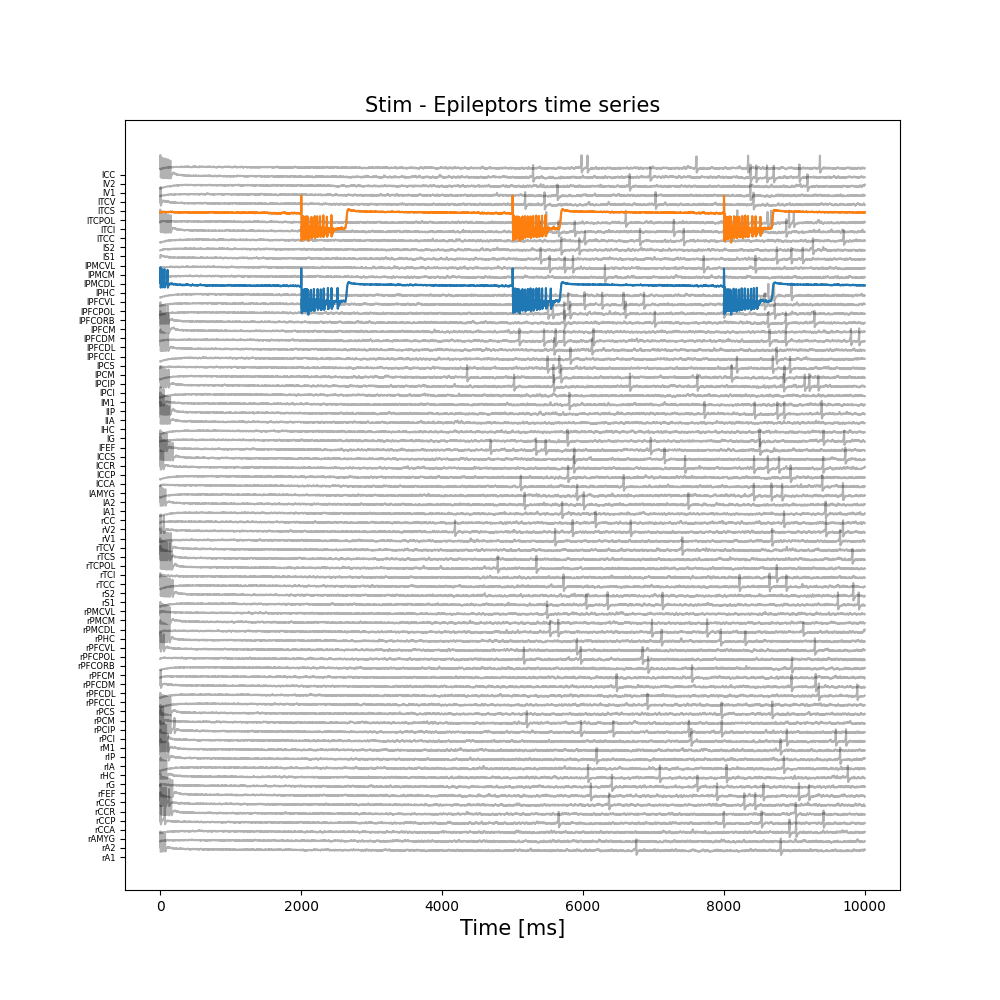

In [33]:
plt.figure(figsize=(10,10))
plt.plot(t[:], tavg[:, 0, :, 0] + np.r_[:nregions], 'k', alpha=0.3)
plt.title('Stim - Epileptors time series', fontsize=15)
plt.xlabel('Time [ms]', fontsize=15)
plt.yticks(np.arange(len(con.region_labels)), con.region_labels, fontsize=6)

for i, node in enumerate(nodes):
    plt.plot(t[:], tavg[:, 0, nodes[i], 0] + nodes[i]); # , 'C0'

# Further exploration

***

* Find less invasive resection strategy for stopping the seizure propagation
    * Effects of a lesion are not local and are difficult to predict without a simulation
    * Comparing the damage of the different surgical procedures
    * resection versus random lesioning versus lesioning the strongest links
* Comparing the impact of the stimuli for trigerring seiuzure
    * How strong must the stimulus be for different nodes, with different heatmaps?